# 실습 전에 
---
##### 01. 이미지의 특징 
* Canny edge detection 등의 convolution operation 활용


##### 02. 같은 특징을 찾는 방법
* template matching으로 유사한 픽셀 혹은 영역 탐색
---

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

torch.manual_seed(42)

# 입력 shape: (N, 1, 28, 28)
x = torch.randn(8, 1, 28, 28)

cnn = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2, padding=1),

    nn.Flatten(start_dim=1),
    nn.Linear(2048, 625),
    nn.ReLU(),
    nn.Dropout(),
    nn.Linear(625, 10),
)

print('입력 shape:', tuple(x.shape))
print(cnn)


입력 shape: (8, 1, 28, 28)
Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=1, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=2048, out_features=625, bias=True)
  (11): ReLU()
  (12): Dropout(p=0.5, inplace=False)
  (13): Linear(in_features=625, out_features=10, bias=True)
)


## 1. 각 층의 예상 output shape와 실제 output shape

아래 CNN을 실행하기 전에 각 Layer의 예상 shape를 적고, 실제 값과 비교한다.

1. `Conv2d(1,32,3,padding=1)` → `ReLU()` → `MaxPool2d(2)`
2. `Conv2d(32,64,3,padding=1)` → `ReLU()` → `MaxPool2d(2)`
3. `Conv2d(64,128,3,padding=1)` → `ReLU()` → `MaxPool2d(2,padding=1)`
4. `Flatten(start_dim=1)` → `Linear(2048,625)` → `ReLU()`
5. `Dropout()` → `Linear(625,10)`


In [25]:
expected_shapes = [
    ("Conv2d(1,32,3,padding=1)", "(N, 32, 28, 28)"),
    ("ReLU()", "(N, 32, 28, 28)"),
    ("MaxPool2d(2)", "(N, 32, 14, 14)"),
    ("Conv2d(32,64,3,padding=1)", "(N, 64, 14, 14)"),
    ("ReLU()", "(N, 64, 14, 14)"),
    ("MaxPool2d(2)", "(N, 64, 7, 7)"),
    ("Conv2d(64,128,3,padding=1)", "(N, 128, 7, 7)"),
    ("ReLU()", "(N, 128, 7, 7)"),
    ("MaxPool2d(2,padding=1)", "(N, 128, 4, 4)"),
    ("Flatten(start_dim=1)", "(N, 2048)"),
    ("Linear(2048,625)", "(N, 625)"),
    ("ReLU()", "(N, 625)"),
    ("Dropout()", "(N, 625)"),
    ("Linear(625,10)", "(N, 10)"),
]

records = []
tmp = x
for layer, (name, expected) in zip(cnn, expected_shapes):
    tmp = layer(tmp)
    records.append({
        'Layer': name,
        '예상 output shape': expected,
        '실제 output shape': str(tuple(tmp.shape)),
    })

shape_df = pd.DataFrame(records)
display(shape_df)
print('최종 출력 shape:', tuple(tmp.shape))
assert tuple(tmp.shape) == (8, 10)


,Layer,예상 output shape,실제 output shape
0,"Conv2d(1,32,3,padding=1)","(N, 32, 28, 28)","(8, 32, 28, 28)"
1,ReLU(),"(N, 32, 28, 28)","(8, 32, 28, 28)"
2,MaxPool2d(2),"(N, 32, 14, 14)","(8, 32, 14, 14)"
3,"Conv2d(32,64,3,padding=1)","(N, 64, 14, 14)","(8, 64, 14, 14)"
4,ReLU(),"(N, 64, 14, 14)","(8, 64, 14, 14)"
5,MaxPool2d(2),"(N, 64, 7, 7)","(8, 64, 7, 7)"
6,"Conv2d(64,128,3,padding=1)","(N, 128, 7, 7)","(8, 128, 7, 7)"
7,ReLU(),"(N, 128, 7, 7)","(8, 128, 7, 7)"
8,"MaxPool2d(2,padding=1)","(N, 128, 4, 4)","(8, 128, 4, 4)"
9,Flatten(start_dim=1),"(N, 2048)","(8, 2048)"


최종 출력 shape: (8, 10)


### 해석

- `Conv2d`는 입력 채널 수를 유지하면서 출력 채널 수를 변경한다.
- `padding=1`이므로 공간 크기가 유지되고, `MaxPool2d(2)`는 절반으로 줄어든다.
- 마지막 `MaxPool2d(2,padding=1)`는 `7x7` 입력을 `4x4`로 줄인다.
- `128 * 4 * 4 = 2048`이므로 `Flatten` 후 `Linear(2048,625)`의 입력 크기가 정확히 맞는다.
- 최종 출력은 `(N, 10)`이며, 분류할 클래스 수가 10개이기 때문에 맞는 형태이다.
- 이번 CNN에서는 예상 shape와 실제 shape가 완전히 일치한다. 만약 다르다면 보통 `padding`이나 `MaxPool2d`에서 공간 크기 계산 차이가 원인이다.


In [26]:
cnn.eval()
batch_records = []
for N in [1, 8, 32]:
    x_batch = torch.randn(N, 1, 28, 28)
    with torch.no_grad():
        y_batch = cnn(x_batch)
    param_count = sum(p.numel() for p in cnn.parameters())
    batch_records.append({
        'N': N,
        '최종 출력 shape': tuple(y_batch.shape),
        'Parameter 수': param_count,
    })

batch_df = pd.DataFrame(batch_records)
display(batch_df)
print('모든 출력 shape가 (N,10)인가?', all(tuple(row['최종 출력 shape']) == (row['N'], 10) for _, row in batch_df.iterrows()))
print('모든 Parameter 수가 같은가?', len({row['Parameter 수'] for _, row in batch_df.iterrows()}) == 1)


,N,최종 출력 shape,Parameter 수
0,1,"(1, 10)",1379557
1,8,"(8, 10)",1379557
2,32,"(32, 10)",1379557


모든 출력 shape가 (N,10)인가? True
모든 Parameter 수가 같은가? True


In [27]:
layer_param_rows = []
for layer_name, layer in zip(
    [
        'Conv2d(1,32,3,padding=1)',
        'ReLU()',
        'MaxPool2d(2)',
        'Conv2d(32,64,3,padding=1)',
        'ReLU()',
        'MaxPool2d(2)',
        'Conv2d(64,128,3,padding=1)',
        'ReLU()',
        'MaxPool2d(2,padding=1)',
        'Flatten(start_dim=1)',
        'Linear(2048,625)',
        'ReLU()',
        'Dropout()',
        'Linear(625,10)',
    ],
    cnn,
):
    param_count = sum(p.numel() for p in layer.parameters())
    layer_param_rows.append({
        'Layer': layer_name,
        'Number of Parameters': param_count,
        '학습 가능한 Parameter 유무': '있음' if param_count > 0 else '없음',
    })

layer_param_df = pd.DataFrame(layer_param_rows)
display(layer_param_df)


,Layer,Number of Parameters,학습 가능한 Parameter 유무
0,"Conv2d(1,32,3,padding=1)",320,있음
1,ReLU(),0,없음
2,MaxPool2d(2),0,없음
3,"Conv2d(32,64,3,padding=1)",18496,있음
4,ReLU(),0,없음
5,MaxPool2d(2),0,없음
6,"Conv2d(64,128,3,padding=1)",73856,있음
7,ReLU(),0,없음
8,"MaxPool2d(2,padding=1)",0,없음
9,Flatten(start_dim=1),0,없음


## 2. Batch Size와 Parameter 수 비교

다음 코드는 `N ∈ {1, 8, 32}`에 대해 최종 출력 shape와 전체 parameter 수를 비교한다.

- 출력 shape는 `(N, 10)`이어야 한다.
- parameter 수는 모델 구조가 동일하므로 세 행에서 모두 같아야 한다.

아래 표를 보면 배치 크기가 달라도 파라미터 수는 변하지 않는다.


### Layer별 학습 가능한 Parameter 여부

- `Conv2d`와 `Linear`만 학습 가능한 parameter를 가진다.
- `ReLU`, `MaxPool2d`, `Flatten`, `Dropout`은 parameter가 없다.
- 전체 parameter 수는 각 `Conv2d`와 `Linear`의 수를 모두 더한 값이다.


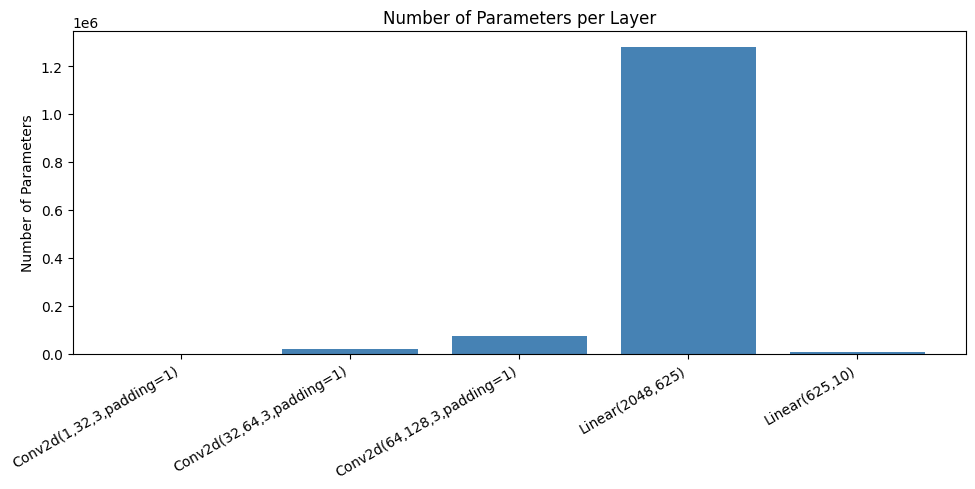

In [28]:
param_bar = layer_param_df.copy()
param_bar = param_bar[param_bar['Number of Parameters'] > 0]

plt.figure(figsize=(10, 5))
plt.bar(param_bar['Layer'], param_bar['Number of Parameters'], color='steelblue')
plt.xticks(rotation=30, ha='right')
plt.ylabel('Number of Parameters')
plt.title('Number of Parameters per Layer')
plt.tight_layout()
plt.show()


## 선택 실습
**입력 영상 크기와 Linear 입력 크기가 맞지 않는 경우**

아래 코드를 노트북 가장 아래에 추가해 실행한다.


In [29]:
small = nn.Sequential(
    nn.Conv2d(1, 4, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(4, 8, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(8 * 7 * 7, 10),
)

for side in [32, 28]:
    debug_image = torch.randn(1, 1, side, side)
    with torch.no_grad():
        debug_features = small[:-1](debug_image)
        print('Input:', debug_image.shape,
              'Flatten:', debug_features.shape,
              'Linear in_features:', small[-1].in_features)
        try:
            print('Output:', small(debug_image).shape)
        except (RuntimeError, ValueError) as error:
            print(type(error).__name__, str(error))


Input: torch.Size([1, 1, 32, 32]) Flatten: torch.Size([1, 512]) Linear in_features: 392
RuntimeError mat1 and mat2 shapes cannot be multiplied (1x512 and 392x10)
Input: torch.Size([1, 1, 28, 28]) Flatten: torch.Size([1, 392]) Linear in_features: 392
Output: torch.Size([1, 10])


| 입력 영상 크기 | Flatten shape | Linear in_features | 실행 결과 |
|---|---:|---:|---|
| 32 | (1, 512) | 392 | 실패: `Linear`는 392개를 기대하지만 512개가 들어와서 오류 발생 |
| 28 | (1, 392) | 392 | 성공: 출력 shape = `(1, 10)` |

- 32x32 입력은 2번의 `MaxPool2d(2)` 이후 `8x8`이 되어 Flatten 수가 512개가 된다.
- 28x28 입력은 2번의 `MaxPool2d(2)` 이후 `7x7`이 되어 Flatten 수가 392개가 되고, `Linear(392,10)`과 정확히 맞는다.
- 즉, `Linear`가 요구하는 입력 수와 일치하지 않으면 `RuntimeError` 또는 `ValueError`가 발생한다.
